# Early Warning System (EWS) Siswa Berisiko - Moodle OULAD
### Sistem Deteksi Dini & Generator Payload JSON untuk AI SLM (Bimbingan Konseling)

Notebook ini menerapkan pipeline Machine Learning untuk mendeteksi siswa berisiko (*fail / withdrawn*) berdasarkan log Moodle (OULAD) pada batas waktu hari ke-60 (*cut-off day 60*).
Fitur yang diekstraksi mencakup 3 pilar indikator BK:
1. **Engagement Indicator**: Keaktifan akses VLE, durasi inaktif, rasio momentum 14 hari terakhir, materi unik diakses.
2. **Task & Discipline Indicator**: Tugas terlewat (*missing assignment*), keterlambatan (*overdue*), selisih deadline, dan pola prokrastinasi.
3. **Academic Risk Indicator**: Nilai kuis/asesmen di bawah standar (KKM), deviasi terhadap modul (*z-score*), tren penurunan nilai (*grade drop*), kuis otomatis (CMA), dan riwayat pengulangan.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_fscore_support

# Visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Load Data OULAD
student_info = pd.read_csv('studentInfo.csv')
student_vle = pd.read_csv('studentVle.csv')
student_assessment = pd.read_csv('studentAssessment.csv')
assessments = pd.read_csv('assessments.csv')

print("Ukuran Data Awal:")
print(f"- Data Siswa & Status: {student_info.shape[0]:,} baris")
print(f"- Log Interaksi VLE:   {student_vle.shape[0]:,} baris")
print(f"- Nilai Asesmen Siswa: {student_assessment.shape[0]:,} baris")
print(f"- Jadwal Asesmen:      {assessments.shape[0]:,} baris")

Ukuran Data Awal:
- Data Siswa & Status: 32,593 baris
- Log Interaksi VLE:   10,655,280 baris
- Nilai Asesmen Siswa: 173,912 baris
- Jadwal Asesmen:      206 baris


## 1. Filter Cut-Off Hari ke-60
Data interaksi dan asesmen hanya dihitung sampai **hari ke-60** perkuliahan/semester. Hal ini menjamin tidak terjadi *data leakage* (kebocoran data masa depan) dan sistem dapat memberikan peringatan sedini mungkin kepada Guru BK / Wali Kelas.

In [11]:
CUT_OFF_DAY = 60

# 1. Filter log VLE sampai hari ke-60
vle_early = student_vle[student_vle['date'] <= CUT_OFF_DAY].copy()

# 2. Gabungkan asesmen dengan jadwal deadline
assessment_merged = pd.merge(student_assessment, assessments, on='id_assessment')

# 3. Filter asesmen yang tenggat waktunya ada sebelum/sampai hari ke-60
assessment_early = assessment_merged[assessment_merged['date'] <= CUT_OFF_DAY].copy()

print(f"Log VLE dalam batas cut-off (<= day {CUT_OFF_DAY}): {vle_early.shape[0]:,} baris")
print(f"Asesmen dalam batas cut-off (<= day {CUT_OFF_DAY}): {assessment_early.shape[0]:,} baris")

Log VLE dalam batas cut-off (<= day 60): 4,499,256 baris
Asesmen dalam batas cut-off (<= day 60): 47,259 baris


## 2. Feature Engineering Multi-Indikator BK (Anti-Underfitting)
Tahap ini mengekstraksi 3 kelompok parameter penting untuk Guru BK guna mengatasi *underfitting*:
* **A. Indikator Perilaku & Keaktifan Belajar (Engagement)**: `days_inactive`, `is_inactive_gt_5d`, `is_inactive_gt_14d`, `total_clicks`, `active_days`, `clicks_per_active_day`, `unique_sites_accessed`, dan `clicks_last_14d_ratio` (deteksi penurunan drastis aktivitas di 2 minggu terakhir).
* **B. Indikator Disiplin & Kepatuhan Tugas**: `missing_assignments` (tugas belum dikumpul saat due date lewat), `late_submission_count`, `avg_submission_gap`, dan `procrastination_count` (tugas dikumpul $\le 1$ hari sebelum deadline).
* **C. Indikator Akademik & Pemahaman**: `avg_score`, `min_score`, `score_rel_to_module` (normalisasi z-score per modul), `failing_tasks_count` (nilai $< 40$), `grade_trend` (tren nilai pertama vs terakhir), `cma_quiz_count`, `num_of_prev_attempts`, dan `studied_credits`.

In [12]:
# ==========================================
# A. INDIKATOR PERILAKU & KEAKTIFAN (ENGAGEMENT)
# ==========================================
# A.1 Aktivitas dasar dan inaktivitas
vle_features = vle_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    last_active_date=('date', 'max'),
    unique_sites_accessed=('id_site', 'nunique')
).reset_index()

vle_features['days_inactive'] = CUT_OFF_DAY - vle_features['last_active_date']
vle_features['is_inactive_gt_5d'] = (vle_features['days_inactive'] > 5).astype(int)
vle_features['is_inactive_gt_14d'] = (vle_features['days_inactive'] >= 14).astype(int)
vle_features['clicks_per_active_day'] = vle_features['total_clicks'] / (vle_features['active_days'] + 1e-5)
vle_features.drop(columns=['last_active_date'], inplace=True)

# A.2 Momentum / Tren 14 Hari Terakhir (Day 47-60)
vle_last_14d = vle_early[vle_early['date'] >= (CUT_OFF_DAY - 14)].groupby(
    ['code_module', 'code_presentation', 'id_student']
)['sum_click'].sum().reset_index(name='clicks_last_14d')

vle_features = pd.merge(vle_features, vle_last_14d, on=['code_module', 'code_presentation', 'id_student'], how='left')
vle_features['clicks_last_14d'] = vle_features['clicks_last_14d'].fillna(0)
vle_features['clicks_last_14d_ratio'] = vle_features['clicks_last_14d'] / (vle_features['total_clicks'] + 1)

# ==========================================
# B & C. DISIPLIN TUGAS & RISIKO AKADEMIK
# ==========================================
assessment_early['is_late'] = assessment_early['date_submitted'] > assessment_early['date']
assessment_early['submission_gap'] = assessment_early['date_submitted'] - assessment_early['date']
assessment_early['is_procrastinated'] = (assessment_early['date_submitted'] >= (assessment_early['date'] - 1)) & (~assessment_early['is_late'])
assessment_early['is_failing'] = assessment_early['score'] < 40

# Asesmen dasar
assessment_features = assessment_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    tasks_submitted=('id_assessment', 'count'),
    late_submission_count=('is_late', 'sum'),
    avg_submission_gap=('submission_gap', 'mean'),
    procrastination_count=('is_procrastinated', 'sum'),
    avg_score=('score', 'mean'),
    min_score=('score', 'min'),
    failing_tasks_count=('is_failing', 'sum')
).reset_index()

# Tren Nilai: Selisih nilai tugas terakhir vs tugas pertama
sorted_asm = assessment_early.sort_values(by=['code_module', 'code_presentation', 'id_student', 'date'])
first_scores = sorted_asm.groupby(['code_module', 'code_presentation', 'id_student'])['score'].first().reset_index(name='first_score')
last_scores = sorted_asm.groupby(['code_module', 'code_presentation', 'id_student'])['score'].last().reset_index(name='last_score')
trend_scores = pd.merge(first_scores, last_scores, on=['code_module', 'code_presentation', 'id_student'])
trend_scores['grade_trend'] = trend_scores['last_score'] - trend_scores['first_score']
trend_scores.drop(columns=['first_score', 'last_score'], inplace=True)
assessment_features = pd.merge(assessment_features, trend_scores, on=['code_module', 'code_presentation', 'id_student'], how='left')

# Kuis Komputer (CMA)
cma_asm = assessment_early[assessment_early['assessment_type'] == 'CMA'].groupby(
    ['code_module', 'code_presentation', 'id_student']
).agg(
    cma_quiz_count=('id_assessment', 'count'),
    cma_avg_score=('score', 'mean')
).reset_index()
assessment_features = pd.merge(assessment_features, cma_asm, on=['code_module', 'code_presentation', 'id_student'], how='left')

# Total tugas yang sudah jatuh tempo per modul
tasks_due_per_course = assessments[assessments['date'] <= CUT_OFF_DAY].groupby(
    ['code_module', 'code_presentation']
)['id_assessment'].nunique().reset_index(name='total_tasks_due')

# ==========================================
# D. MERGE ALL KE DATA UTAMA
# ==========================================
base_cols = ['code_module', 'code_presentation', 'id_student', 'num_of_prev_attempts', 'studied_credits', 'final_result']
df_final = pd.merge(student_info[base_cols], vle_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_final = pd.merge(df_final, assessment_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_final = pd.merge(df_final, tasks_due_per_course, on=['code_module', 'code_presentation'], how='left')

# Imputasi logis untuk nilai kosong
df_final['total_tasks_due'] = df_final['total_tasks_due'].fillna(0)
df_final['tasks_submitted'] = df_final['tasks_submitted'].fillna(0)
df_final['missing_assignments'] = np.maximum(0, df_final['total_tasks_due'] - df_final['tasks_submitted'])
df_final['total_clicks'] = df_final['total_clicks'].fillna(0)
df_final['active_days'] = df_final['active_days'].fillna(0)
df_final['unique_sites_accessed'] = df_final['unique_sites_accessed'].fillna(0)
df_final['days_inactive'] = df_final['days_inactive'].fillna(CUT_OFF_DAY)
df_final['is_inactive_gt_5d'] = df_final['is_inactive_gt_5d'].fillna(1)
df_final['is_inactive_gt_14d'] = df_final['is_inactive_gt_14d'].fillna(1)
df_final['clicks_per_active_day'] = df_final['clicks_per_active_day'].fillna(0)
df_final['clicks_last_14d'] = df_final['clicks_last_14d'].fillna(0)
df_final['clicks_last_14d_ratio'] = df_final['clicks_last_14d_ratio'].fillna(0)

df_final['late_submission_count'] = df_final['late_submission_count'].fillna(0)
df_final['avg_submission_gap'] = df_final['avg_submission_gap'].fillna(0)
df_final['procrastination_count'] = df_final['procrastination_count'].fillna(0)
df_final['avg_score'] = df_final['avg_score'].fillna(0)
df_final['min_score'] = df_final['min_score'].fillna(0)
df_final['failing_tasks_count'] = df_final['failing_tasks_count'].fillna(0)
df_final['grade_trend'] = df_final['grade_trend'].fillna(0)
df_final['cma_quiz_count'] = df_final['cma_quiz_count'].fillna(0)
df_final['cma_avg_score'] = df_final['cma_avg_score'].fillna(0)

# Normalisasi nilai relatif per modul
module_avg = df_final.groupby(['code_module', 'code_presentation'])['avg_score'].transform('mean')
df_final['score_rel_to_module'] = df_final['avg_score'] - module_avg

# Target: 1 = Berisiko (Fail / Withdrawn), 0 = Aman (Pass / Distinction)
df_final['is_at_risk'] = df_final['final_result'].apply(lambda x: 1 if x in ['Fail', 'Withdrawn'] else 0)

print("Dataset Siap untuk Modeling:")
print(f"Total baris: {len(df_final):,}")
print(f"Proporsi Siswa Berisiko: {df_final['is_at_risk'].mean():.2%}")

Dataset Siap untuk Modeling:
Total baris: 32,593
Proporsi Siswa Berisiko: 52.80%


## 3. Split Cohort & Definisi Fitur (Train: 2013, Test: 2014)
Data dibagi berdasarkan kohor tahun ajaran (*out-of-cohort evaluation*):
* **Latih (Train)**: Semester 2013J dan 2013B
* **Uji (Test)**: Semester 2014J dan 2014B
Pemisahan ini memastikan model diuji pada data tahun yang belum pernah dilihat sama sekali, mensimulasikan penerapan riil pada tahun ajaran baru.

In [13]:
feature_cols = [
    # A. Engagement Indicator
    'total_clicks', 
    'active_days', 
    'days_inactive',
    'is_inactive_gt_5d',
    'is_inactive_gt_14d',
    'clicks_per_active_day',
    'clicks_last_14d_ratio',
    'unique_sites_accessed',
    # B. Task & Discipline Indicator
    'missing_assignments', 
    'late_submission_count', 
    'avg_submission_gap',
    'procrastination_count',
    # C. Academic Risk Indicator
    'avg_score', 
    'min_score',
    'score_rel_to_module',
    'failing_tasks_count',
    'grade_trend',
    'cma_quiz_count',
    # D. Konteks Kerentanan Siswa
    'num_of_prev_attempts',
    'studied_credits'
]

# Split berbasis kohor tahun ajaran
train_mask = df_final['code_presentation'].str.startswith('2013')
test_mask = df_final['code_presentation'].str.startswith('2014')

X_train, y_train = df_final.loc[train_mask, feature_cols], df_final.loc[train_mask, 'is_at_risk']
X_test, y_test = df_final.loc[test_mask, feature_cols], df_final.loc[test_mask, 'is_at_risk']

print(f"Total Fitur yang Digunakan: {len(feature_cols)} fitur")
print(f"Jumlah Data Latih (Kohor 2013): {len(X_train):,} siswa")
print(f"Jumlah Data Uji (Kohor 2014):   {len(X_test):,} siswa")

Total Fitur yang Digunakan: 20 fitur
Jumlah Data Latih (Kohor 2013): 13,529 siswa
Jumlah Data Uji (Kohor 2014):   19,064 siswa


## 4. Pelatihan Model dengan 5-Fold Stratified CV & Kalibrasi Probabilitas (Anti-Overfitting)
Untuk mencegah *overfitting*:
1. Menerapkan regularisasi pada *Random Forest* (`max_depth=10`, `min_samples_leaf=5`, `min_samples_split=10`, `class_weight='balanced'`).
2. Validasi silang **5-Fold Stratified Cross-Validation** pada kohor latih (2013) untuk mengukur stabilitas performa.
3. Menggunakan **`CalibratedClassifierCV` (Sigmoid)** agar probabilitas risiko yang dihasilkan akurat dan tidak bias saat diparsing ke AI SLM.

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    min_samples_split=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# 1. Evaluasi 5-Fold Cross Validation pada Kohor Latih 2013
cv_scores = cross_val_score(base_rf, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f"5-Fold CV ROC-AUC (Kohor 2013): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# 2. Kalibrasi Probabilitas Model menggunakan 5-Fold Stratified CV
calibrated_model = CalibratedClassifierCV(estimator=base_rf, method='sigmoid', cv=skf)
calibrated_model.fit(X_train, y_train)
print("Model berhasil dilatih dan dikalibrasi!")

5-Fold CV ROC-AUC (Kohor 2013): 0.8801 (+/- 0.0066)
Model berhasil dilatih dan dikalibrasi!


## 5. Evaluasi Out-of-Cohort pada Data Uji 2014
Evaluasi performa model terkalibrasi pada siswa kohor 2014 (data yang belum pernah dilihat).

=== LAPORAN EVALUASI OUT-OF-COHORT (TEST 2014 - DEFAULT THRESHOLD 0.50) ===
              precision    recall  f1-score   support

    Aman (0)       0.75      0.79      0.77      8815
Berisiko (1)       0.81      0.78      0.79     10249

    accuracy                           0.78     19064
   macro avg       0.78      0.78      0.78     19064
weighted avg       0.78      0.78      0.78     19064

ROC-AUC Score: 0.8713


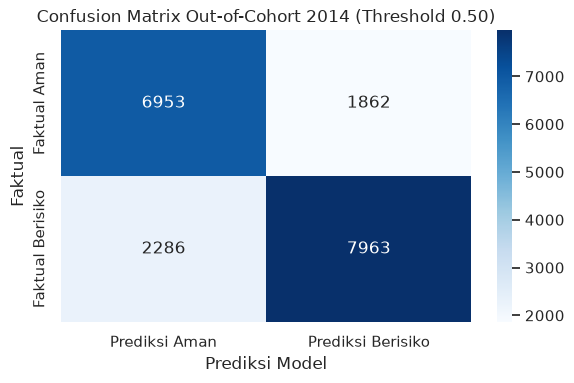

In [15]:
y_prob = calibrated_model.predict_proba(X_test)[:, 1]
y_pred_default = (y_prob >= 0.50).astype(int)

print("=== LAPORAN EVALUASI OUT-OF-COHORT (TEST 2014 - DEFAULT THRESHOLD 0.50) ===")
print(classification_report(y_test, y_pred_default, target_names=['Aman (0)', 'Berisiko (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_default)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Prediksi Aman', 'Prediksi Berisiko'],
            yticklabels=['Faktual Aman', 'Faktual Berisiko'])
plt.title('Confusion Matrix Out-of-Cohort 2014 (Threshold 0.50)')
plt.ylabel('Faktual')
plt.xlabel('Prediksi Model')
plt.tight_layout()
plt.show()

## 6. Kalibrasi Threshold Risiko untuk Guru BK
Bagi Guru BK, meminimalkan *False Negative* (siswa berisiko yang terlewat tanpa bantuan) jauh lebih penting dibanding *False Positive*. Oleh karena itu, threshold keputusan diturunkan dari 0.50 ke nilai optimal guna memaksimalkan *Recall*.

In [16]:
print("Evaluasi Trade-off Threshold untuk Sistem EWS BK:")
print("-" * 58)
print(f"{'Threshold':<10} | {'Precision (1)':<15} | {'Recall (1)':<15} | {'F1-Score'}")
print("-" * 58)

for th in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    yp = (y_prob >= th).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test, yp, average=None)
    flag = " [Rekomendasi BK]" if th == 0.40 else ""
    print(f"{th:<10.2f} | {p[1]:<15.2%} | {r[1]:<15.2%} | {f[1]:.4f}{flag}")

# Terapkan Threshold Terpilih (0.40)
OPTIMAL_THRESHOLD = 0.40
y_pred_calibrated = (y_prob >= OPTIMAL_THRESHOLD).astype(int)
print(f"\n=== HASIL SETELAH KALIBRASI THRESHOLD {OPTIMAL_THRESHOLD:.2f} ===")
print(classification_report(y_test, y_pred_calibrated, target_names=['Aman (0)', 'Berisiko (1)']))

Evaluasi Trade-off Threshold untuk Sistem EWS BK:
----------------------------------------------------------
Threshold  | Precision (1)   | Recall (1)      | F1-Score
----------------------------------------------------------
0.30       | 73.43%          | 86.68%          | 0.7951
0.35       | 75.89%          | 84.04%          | 0.7976
0.40       | 78.05%          | 81.82%          | 0.7989 [Rekomendasi BK]
0.45       | 79.70%          | 79.63%          | 0.7966
0.50       | 81.05%          | 77.70%          | 0.7934
0.55       | 82.45%          | 75.76%          | 0.7896
0.60       | 83.79%          | 73.55%          | 0.7834

=== HASIL SETELAH KALIBRASI THRESHOLD 0.40 ===
              precision    recall  f1-score   support

    Aman (0)       0.78      0.73      0.75      8815
Berisiko (1)       0.78      0.82      0.80     10249

    accuracy                           0.78     19064
   macro avg       0.78      0.78      0.78     19064
weighted avg       0.78      0.78      0.78  

## 7. Feature Importance & Simpan Model
Melihat fitur mana dari 3 kelompok indikator BK yang paling berkontribusi terhadap prediksi risiko siswa, lalu menyimpan model beserta metadatanya.

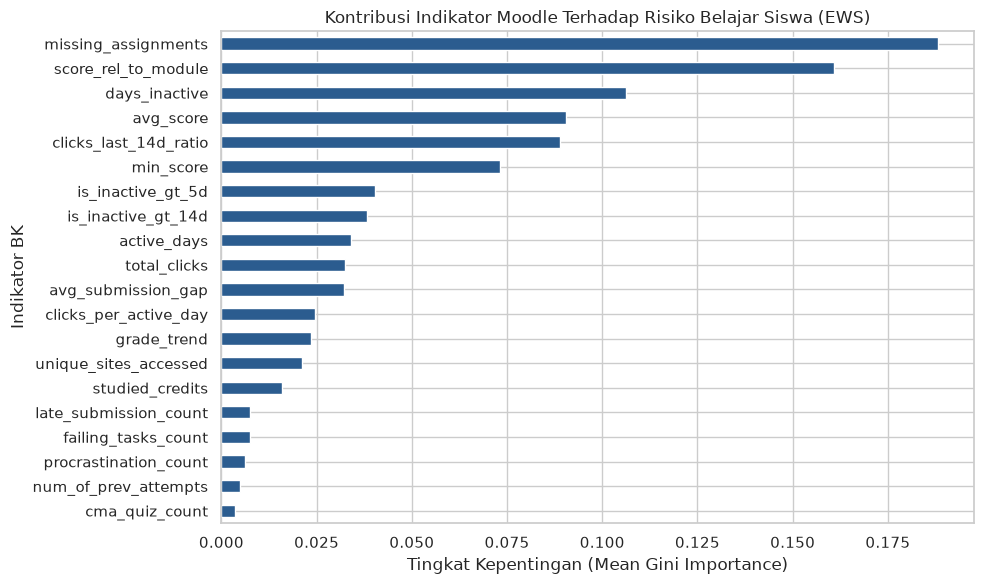

Model dan metadata berhasil disimpan ke 'ews_moodle_model.pkl'!


In [17]:
# Ekstraksi rata-rata feature importance dari sub-estimator model kalibrasi
importances = pd.Series(
    np.mean([clf.estimator.feature_importances_ for clf in calibrated_model.calibrated_classifiers_], axis=0),
    index=feature_cols
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='#2b5c8f')
plt.title('Kontribusi Indikator Moodle Terhadap Risiko Belajar Siswa (EWS)')
plt.xlabel('Tingkat Kepentingan (Mean Gini Importance)')
plt.ylabel('Indikator BK')
plt.tight_layout()
plt.show()

# Simpan model beserta metadata
joblib.dump({
    'model': calibrated_model,
    'features': feature_cols,
    'optimal_threshold': OPTIMAL_THRESHOLD,
    'cut_off_day': CUT_OFF_DAY
}, 'ews_moodle_model.pkl')

print("Model dan metadata berhasil disimpan ke 'ews_moodle_model.pkl'!")

## 8. Generator Payload JSON untuk AI SLM & Integrasi WhatsApp
Bagian ini menyatukan hasil model ML ke format **JSON terstruktur 3 pilar indikator** (Engagement, Task & Discipline, Academic Risk) yang siap diparsing ke **AI SLM (*Small Language Model*)** seperti LLaMA 3.2, Qwen 2.5, atau Phi-3.5 untuk digenerate menjadi narasi pesan WhatsApp yang empatik dan kontekstual.

In [18]:
import json

def generate_ews_json(student_row, probability, threshold=0.40, as_string=True):
    """
    Menghasilkan payload JSON terstruktur 3 Pilar Indikator BK dari hasil deteksi EWS
    untuk diparsing ke AI SLM (Small Language Model) guna pembuatan pesan WhatsApp.
    """
    if probability >= 0.70:
        risk_level = "TINGGI"
        urgency = "Tinggi (butuh intervensi/pemanggilan langsung dalam pekan ini)"
    elif probability >= threshold:
        risk_level = "SEDANG"
        urgency = "Sedang (disarankan pemantauan aktif dan konfirmasi santai ke siswa)"
    else:
        risk_level = "RENDAH"
        urgency = "Rendah (aktivitas belajar masih terpantau aman dan terkontrol)"

    # 1. Deteksi Faktor Pemicu Utama (Berdasarkan Nilai Aktual Siswa)
    triggers = []
    # Pilar A: Engagement
    if student_row['days_inactive'] >= 14:
        triggers.append(f"Tidak aktif di Moodle selama {int(student_row['days_inactive'])} hari berturut-turut.")
    elif student_row['days_inactive'] > 5:
        triggers.append(f"Terdeteksi inaktif di Moodle selama {int(student_row['days_inactive'])} hari terakhir.")
    if student_row['clicks_last_14d_ratio'] < 0.10 and student_row['total_clicks'] > 20:
        triggers.append("Aktivitas 2 minggu terakhir anjlok drastis (kurang dari 10% total aktivitas historis).")
    if student_row['total_clicks'] < 50:
        triggers.append(f"Total frekuensi akses materi sangat minim (hanya {int(student_row['total_clicks'])} klik).")

    # Pilar B: Disiplin Tugas
    if student_row['missing_assignments'] > 0:
        triggers.append(f"Ada {int(student_row['missing_assignments'])} tugas/kuis yang terlewat (belum dikumpulkan).")
    if student_row['late_submission_count'] > 0:
        triggers.append(f"Tercatat {int(student_row['late_submission_count'])} kali mengumpulkan tugas terlambat.")
    if student_row['procrastination_count'] >= 2:
        triggers.append(f"Sering mengumpulkan tugas mepet deadline ({int(student_row['procrastination_count'])} kali indikasi prokrastinasi).")

    # Pilar C: Akademik
    if student_row['avg_score'] < 50 and student_row['tasks_submitted'] > 0:
        triggers.append(f"Rata-rata nilai kuis di bawah standar KKM ({student_row['avg_score']:.1f}/100).")
    if student_row['grade_trend'] < -15:
        triggers.append(f"Tren nilai anjlok drastis ({student_row['grade_trend']:.1f} poin dibanding tugas awal).")
    if student_row['num_of_prev_attempts'] > 0:
        triggers.append(f"Siswa memiliki riwayat mengulang modul ini sebanyak {int(student_row['num_of_prev_attempts'])} kali.")

    if not triggers:
        triggers.append("Pola interaksi menunjukkan penurunan keterlibatan belajar secara umum.")

    # 2. Susun Payload Berdasarkan 3 Pilar Indikator BK
    payload = {
        "student_profile": {
            "id_student": int(student_row['id_student']),
            "course_module": str(student_row['code_module']),
            "semester_presentation": str(student_row['code_presentation']),
            "num_of_prev_attempts": int(student_row['num_of_prev_attempts']),
            "studied_credits": int(student_row['studied_credits'])
        },
        "risk_assessment": {
            "risk_level": risk_level,
            "risk_probability": round(float(probability), 4),
            "risk_percentage": f"{probability:.1%}",
            "decision_threshold": threshold,
            "needs_intervention": bool(probability >= threshold),
            "intervention_urgency": urgency
        },
        "engagement_metrics": {
            "days_inactive": int(student_row['days_inactive']),
            "is_inactive_gt_5d": bool(student_row['is_inactive_gt_5d']),
            "total_clicks": int(student_row['total_clicks']),
            "active_days": int(student_row['active_days']),
            "clicks_last_14d_ratio": round(float(student_row['clicks_last_14d_ratio']), 3),
            "unique_sites_accessed": int(student_row['unique_sites_accessed'])
        },
        "discipline_task_metrics": {
            "missing_assignments": int(student_row['missing_assignments']),
            "late_submission_count": int(student_row['late_submission_count']),
            "avg_submission_gap_days": round(float(student_row['avg_submission_gap']), 1),
            "procrastination_count": int(student_row['procrastination_count'])
        },
        "academic_performance_metrics": {
            "avg_score": round(float(student_row['avg_score']), 1),
            "min_score": round(float(student_row['min_score']), 1),
            "score_rel_to_module": round(float(student_row['score_rel_to_module']), 1),
            "failing_tasks_count": int(student_row['failing_tasks_count']),
            "grade_trend": round(float(student_row['grade_trend']), 1),
            "cma_quiz_count": int(student_row['cma_quiz_count'])
        },
        "detected_risk_factors": triggers,
        "recommended_action": urgency
    }

    if as_string:
        return json.dumps(payload, indent=2, ensure_ascii=False)
    return payload


def create_slm_prompt(ews_json_str, audience="guru_bk"):
    """
    Menyusun prompt terstruktur siap kirim ke AI SLM (Ollama / vLLM / API).
    Pilihan audience: 'guru_bk', 'siswa', atau 'orang_tua'.
    """
    audience_guides = {
        "guru_bk": "Gaya bahasa profesional, padat, dan solutif untuk Guru BK / Wali Kelas. Tampilkan metrik kritis dan rekomendasi tindakan.",
        "siswa": "Gaya bahasa suportif, santun, dan menyemangati langsung ke Siswa. Ajak berdiskusi/konsultasi tanpa nada menghakimi.",
        "orang_tua": "Gaya bahasa santun dan hormat untuk Orang Tua siswa. Ajak bersinergi memantau dan mendampingi belajar anak di rumah."
    }

    prompt = f"""[SYSTEM PROMPT]
Anda adalah asisten AI sistem Early Warning System (EWS) bimbingan konseling dan akademik sekolah.
Tugas Anda adalah membaca data JSON hasil analisis risiko belajar siswa (Engagement, Kepatuhan, Akademik), lalu menghasilkan draf pesan WhatsApp siap kirim.

Aturan Penting:
1. HANYA gunakan fakta dari data JSON (JANGAN mengarang angka atau nilai fiktif).
2. Target Penerima: {audience.upper()} ({audience_guides.get(audience, audience_guides['guru_bk'])}).
3. Gunakan formatting WhatsApp yang rapi (*bold*, poin bullet, emoji relevan) dan batasi panjang pesan agar nyaman dibaca di smartphone.

[DATA SISWA (JSON)]
{ews_json_str}

[INSTRUKSI]
Buatkan draf pesan WhatsApp untuk {audience.upper()} berdasarkan data di atas!
"""
    return prompt


# Template statis (Rule-based) sebagai fallback jika tanpa SLM
def generate_wa_notification(student_row, probability, threshold=0.40):
    """
    Menghasilkan draf notifikasi WhatsApp berbasis template statis (rule-based).
    """
    if probability >= 0.70:
        level_str = "⚠️ TINGGI"
        urgensi = "Siswa butuh intervensi/pemanggilan langsung dalam pekan ini."
    elif probability >= threshold:
        level_str = "🟡 SEDANG"
        urgensi = "Disarankan pemantauan aktif dan konfirmasi santai ke siswa."
    else:
        level_str = "🟢 RENDAH"
        urgensi = "Aktivitas belajar masih terpantau aman dan terkontrol."

    triggers = []
    if student_row['days_inactive'] >= 14:
        triggers.append(f"• Tidak aktif di Moodle selama {int(student_row['days_inactive'])} hari berturut-turut.")
    if student_row['missing_assignments'] > 0:
        triggers.append(f"• Ada {int(student_row['missing_assignments'])} tugas/kuis yang belum dikumpulkan.")
    if student_row['avg_score'] < 50 and student_row['tasks_submitted'] > 0:
        triggers.append(f"• Rata-rata nilai kuis di bawah standar ({student_row['avg_score']:.1f}).")
    if student_row['late_submission_count'] > 0:
        triggers.append(f"• Tercatat {int(student_row['late_submission_count'])} kali mengumpulkan tugas terlambat.")
    if student_row['total_clicks'] < 50:
        triggers.append(f"• Frekuensi akses materi sangat minim (hanya {int(student_row['total_clicks'])} klik).")

    if not triggers:
        triggers.append("• Pola interaksi umum menunjukkan penurunan keterlibatan belajar.")

    trigger_text = "\n".join(triggers)

    pesan = f"""*SISTEM PERINGATAN DINI (EWS) - BIMBINGAN KONSELING*
--------------------------------------------------
*Pemberitahuan Deteksi Risiko Belajar Siswa*

Kepada Yth. Bapak/Ibu Guru BK / Wali Kelas,
Sistem mendeteksi adanya indikasi kendala belajar pada siswa berikut:

👤 *ID Siswa*: {student_row['id_student']}
📚 *Mata Pelajaran*: {student_row['code_module']} ({student_row['code_presentation']})
📊 *Tingkat Risiko*: {level_str} (Probabilitas Risiko: {probability:.1%})

*Faktor Pemicu Risiko (Perilaku Moodle):*
{trigger_text}

*Rekomendasi Tindakan BK:*
{urgensi}

_Pesan otomatis Sistem EWS Moodle AI._
--------------------------------------------------"""
    return pesan


# ==========================================================
# PENGUJIAN: Ekstraksi Sampel Siswa Berisiko Tinggi
# ==========================================================
sample_risk_idx = y_test[y_test == 1].index[0]
sample_student = df_final.loc[sample_risk_idx]
sample_prob = y_prob[X_test.index.get_loc(sample_risk_idx)]

print("=" * 60)
print("1. OUTPUT JSON 3 PILAR INDIKATOR UNTUK AI SLM:")
print("=" * 60)
ews_json_output = generate_ews_json(sample_student, sample_prob, threshold=OPTIMAL_THRESHOLD)
print(ews_json_output)

print("\n" + "=" * 60)
print("2. CONTOH PROMPT SIAP KIRIM KE SLM (AUDIENCE: GURU BK):")
print("=" * 60)
prompt_bk = create_slm_prompt(ews_json_output, audience="guru_bk")
print(prompt_bk)

print("\n" + "=" * 60)
print("3. CONTOH PROMPT UNTUK LANGSUNG KE SISWA:")
print("=" * 60)
prompt_siswa = create_slm_prompt(ews_json_output, audience="siswa")
print(prompt_siswa)

print("\n" + "=" * 60)
print("4. TEMPLATE STATIS (FALLBACK):")
print("=" * 60)
wa_message = generate_wa_notification(sample_student, sample_prob, threshold=OPTIMAL_THRESHOLD)
print(wa_message)

1. OUTPUT JSON 3 PILAR INDIKATOR UNTUK AI SLM:
{
  "student_profile": {
    "id_student": 65002,
    "course_module": "AAA",
    "semester_presentation": "2014J",
    "num_of_prev_attempts": 1,
    "studied_credits": 60
  },
  "risk_assessment": {
    "risk_level": "TINGGI",
    "risk_probability": 0.8817,
    "risk_percentage": "88.2%",
    "decision_threshold": 0.4,
    "needs_intervention": true,
    "intervention_urgency": "Tinggi (butuh intervensi/pemanggilan langsung dalam pekan ini)"
  },
  "engagement_metrics": {
    "days_inactive": 50,
    "is_inactive_gt_5d": true,
    "total_clicks": 3,
    "active_days": 1,
    "clicks_last_14d_ratio": 0.0,
    "unique_sites_accessed": 1
  },
  "discipline_task_metrics": {
    "missing_assignments": 0,
    "late_submission_count": 0,
    "avg_submission_gap_days": -37.5,
    "procrastination_count": 0
  },
  "academic_performance_metrics": {
    "avg_score": 67.0,
    "min_score": 66.0,
    "score_rel_to_module": 4.0,
    "failing_tasks_co